In [62]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder, MultiLabelBinarizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from collections import Counter
import plotly.express as px
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer

In [63]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from scipy.stats import mstats
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import plotly.express as px
from sklearn.decomposition import PCA

In [64]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /Users/maryc/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [65]:
df_ba = pd.read_csv('BusinessAnalyst.csv')
df_da = pd.read_csv('DataAnalyst.csv')
df_de = pd.read_csv('DataEngineer.csv')
df_ds = pd.read_csv('DataScientist.csv')

In [66]:
cols = [
    'Job Title', 'Salary Estimate', 'Job Description', 'Rating',
    'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
    'Type of ownership', 'Industry', 'Sector', 'Revenue',
    'Competitors', 'Easy Apply'
]

In [67]:
df_ba = df_ba[cols]
df_da = df_da[cols]
df_de = df_de[cols]
df_ds = df_ds[cols]

In [68]:
df_ba['role'] = 'BA'
df_da['role'] = 'DA'
df_de['role'] = 'DE'
df_ds['role'] = 'DS'

In [69]:
df = pd.concat([df_ba, df_da, df_de, df_ds], ignore_index=True)

## eda

In [70]:
df.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply,role
0,Business Analyst - Clinical & Logistics Platform,$56K-$102K (Glassdoor est.),Company Overview\n\n\nAt Memorial Sloan Ketter...,3.9,Memorial Sloan-Kettering\n3.9,"New York, NY","New York, NY",10000+ employees,1884,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),"Mayo Clinic, The Johns Hopkins Hospital, MD An...",-1,BA
1,Business Analyst,$56K-$102K (Glassdoor est.),We are seeking for an energetic and collaborat...,3.8,Paine Schwartz Partners\n3.8,"New York, NY","New York, NY",1 to 50 employees,-1,Company - Private,Venture Capital & Private Equity,Finance,Unknown / Non-Applicable,-1,True,BA
2,Data Analyst,$56K-$102K (Glassdoor est.),"For more than a decade, Asembia has been worki...",3.6,Asembia\n3.6,"Florham Park, NJ","Florham Park, NJ",501 to 1000 employees,2004,Company - Private,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$5 to $10 million (USD),-1,-1,BA
3,"Information Security Analyst, Incident Response",$56K-$102K (Glassdoor est.),Job Description Summary\nThe Information Secur...,3.6,BD\n3.6,"Franklin Lakes, NJ","Franklin Lakes, NJ",10000+ employees,1897,Company - Public,Health Care Products Manufacturing,Manufacturing,$10+ billion (USD),"Abbott, Siemens, Baxter",-1,BA
4,Analyst - FP&A Global Revenue,$56K-$102K (Glassdoor est.),Magnite is the world's largest independent sel...,3.4,Rubicon Project\n3.4,"New York, NY","Los Angeles, CA",201 to 500 employees,2007,Company - Public,Internet,Information Technology,$100 to $500 million (USD),"PubMatic, AppNexus, Index Exchange",True,BA


In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12782 entries, 0 to 12781
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Job Title          12782 non-null  object
 1   Salary Estimate    12782 non-null  object
 2   Job Description    12782 non-null  object
 3   Rating             12782 non-null  object
 4   Company Name       12781 non-null  object
 5   Location           12782 non-null  object
 6   Headquarters       12782 non-null  object
 7   Size               12782 non-null  object
 8   Founded            12782 non-null  object
 9   Type of ownership  12782 non-null  object
 10  Industry           12782 non-null  object
 11  Sector             12782 non-null  object
 12  Revenue            12782 non-null  object
 13  Competitors        12382 non-null  object
 14  Easy Apply         12382 non-null  object
 15  role               12782 non-null  object
dtypes: object(16)
memory usage: 1.6+ MB


In [72]:
df.describe(include='all')

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply,role
count,12782,12782,12782,12782.0,12781,12782,12782,12782,12782,12782,12782,12782,12782,12382,12382,12782
unique,5979,464,10340,79.0,4947,411,1035,17,406,33,124,63,15,894,2,4
top,Data Analyst,$43K-$84K (Glassdoor est.),Citi\n3.7,-1.0,"Staffigo Technical Services, LLC\n5.0","New York, NY","New York, NY",10000+ employees,-1,Company - Private,IT Services,Information Technology,Unknown / Non-Applicable,-1,-1,BA
freq,801,84,22,915.0,242,1047,891,2642,2208,6679,1772,3644,3356,8917,11859,4092


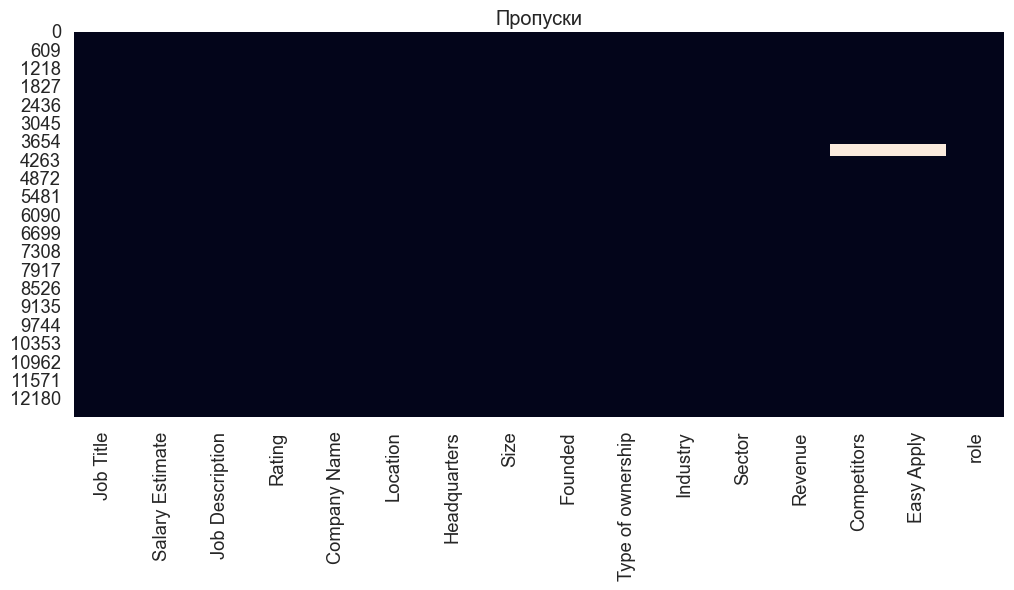

In [73]:
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(12,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Пропуски")
plt.show()

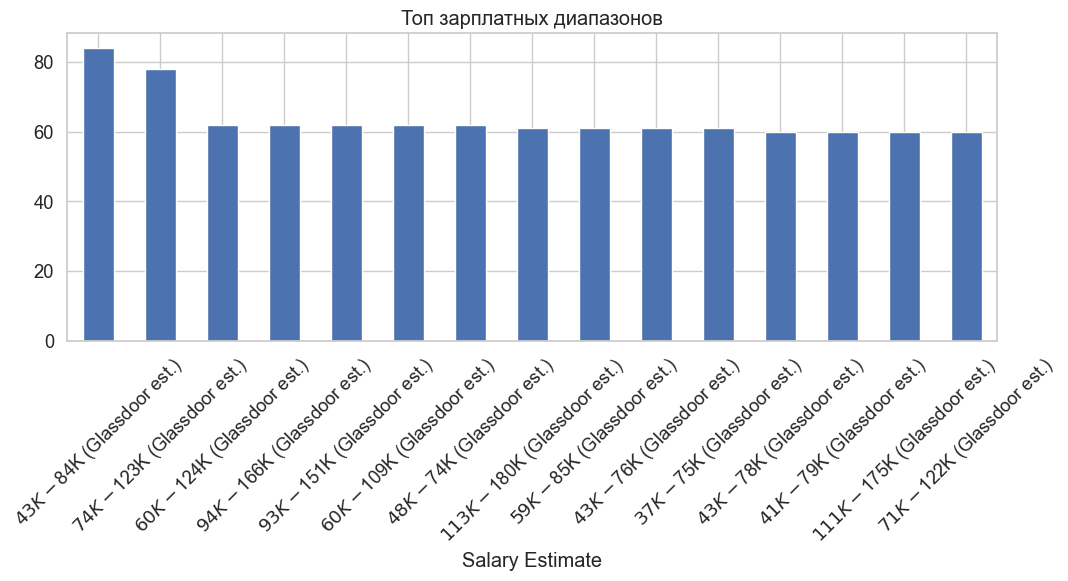

In [74]:
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(12,4))
df['Salary Estimate'].value_counts().head(15).plot(kind='bar')
plt.xticks(rotation=45)
plt.title("Топ зарплатных диапазонов")
plt.show()

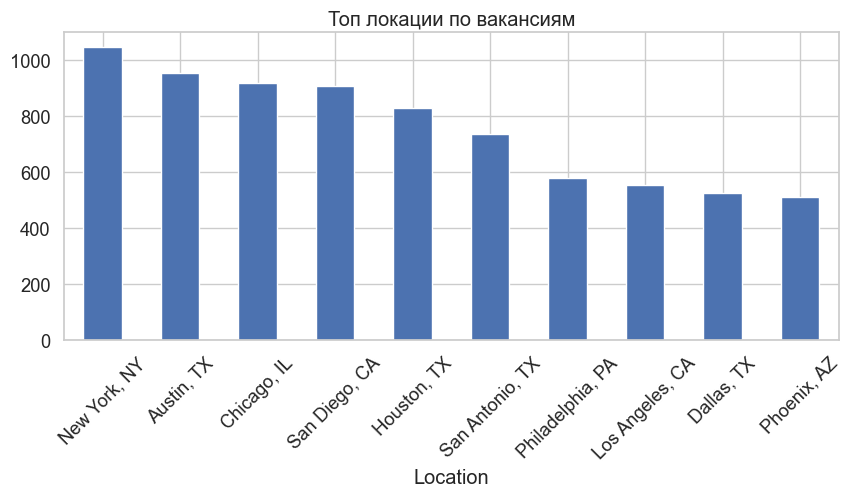

In [75]:
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10,4))
df['Location'].value_counts().head(10).plot(kind='bar')
plt.xticks(rotation=45)
plt.title("Топ локации по вакансиям")
plt.show()

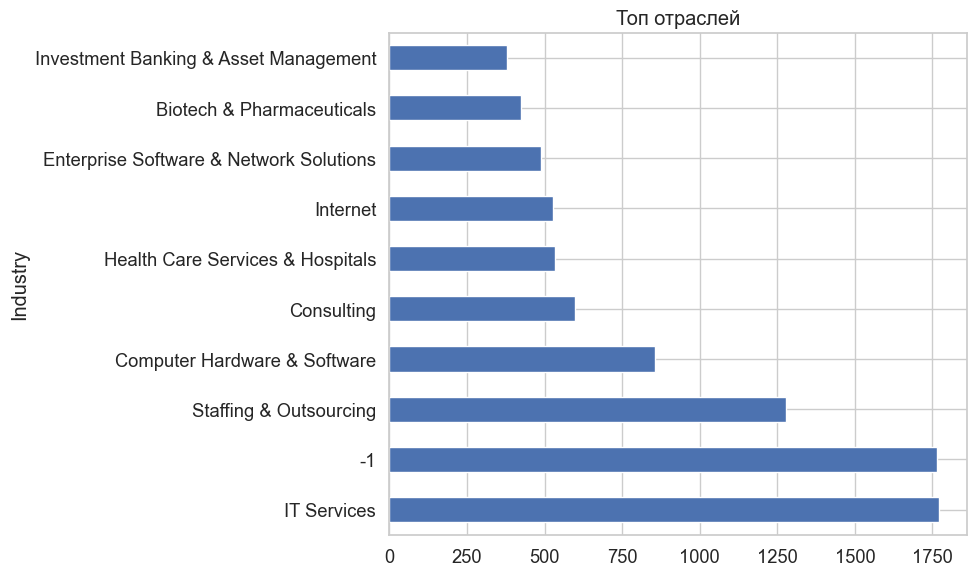

In [76]:
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10,6))
df['Industry'].value_counts().head(10).plot(kind='barh')
plt.title("Топ отраслей")
plt.tight_layout()
plt.show()

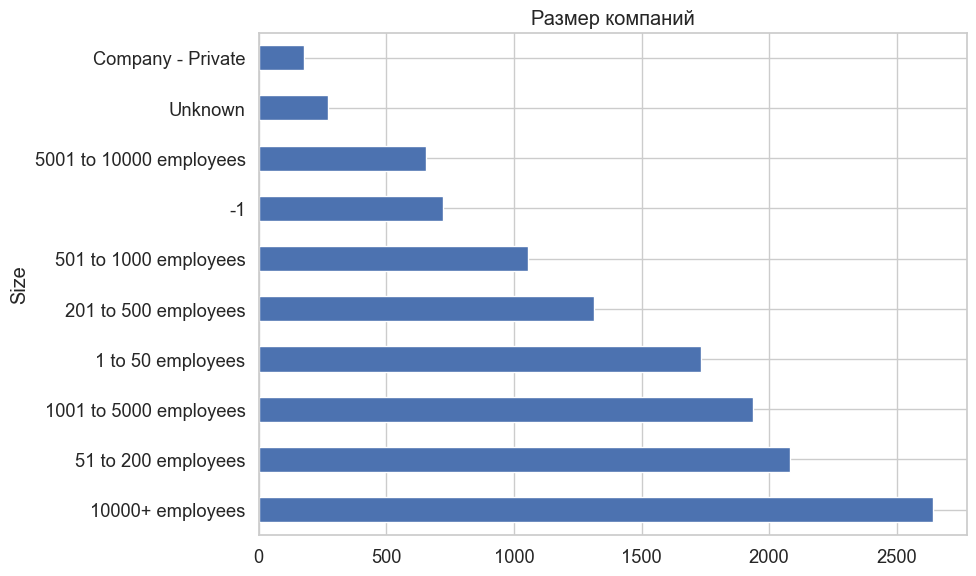

In [77]:
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10,6))
df['Size'].value_counts().head(10).plot(kind='barh')
plt.title("Размер компаний")
plt.tight_layout()
plt.show()

## очистка

In [78]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

Упрощаем job_title

In [79]:
df['job_title'] = df['job_title'].str.split(',').str[0]
df['job_title'] = df['job_title'].str.split('/').str[0]
df['job_title'] = df['job_title'].str.split('-').str[0]
df['job_title'] = df['job_title'].str.strip()

Извлекаем среднюю зарплату

In [80]:
def extract_avg_salary(x):
    if pd.isna(x) or x == '-1':
        return np.nan
    nums = re.findall(r'\$?(\d+)K', str(x))
    if len(nums) == 2:
        return (int(nums[0]) + int(nums[1])) / 2
    elif len(nums) == 1:
        return int(nums[0])
    else:
        return np.nan

In [81]:
df['salary_avg_k'] = df['salary_estimate'].apply(extract_avg_salary)

Рейтинг

In [82]:
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['rating'] = df['rating'].replace(-1.0, np.nan)

Убираем рейтинг из company_name

In [83]:
df['company_name'] = df['company_name'].astype(str)
df['company_name'] = df['company_name'].apply(lambda x: x.split('\n')[0] if '\n' in x else x)
df['company_name'] = df['company_name'].apply(lambda x: re.sub(r'\d\.\d$', '', x).strip())

Location и Headquarters - только город

In [84]:
df['location_city'] = df['location'].str.split(',').str[0].str.strip()
df['hq_city'] = df['headquarters'].str.split(',').str[0].str.strip()

Size в среднее количество сотрудников

In [85]:
def clean_size(x):
    if pd.isna(x) or x in ['-1', 'Unknown']:
        return np.nan
    x = str(x)
    if 'to' in x:
        a, b = x.split('to')
        a = re.findall(r'\d+', a)[0]
        b = re.findall(r'\d+', b)[0]
        return (int(a) + int(b)) / 2
    elif '+' in x:
        return int(re.findall(r'\d+', x)[0]) + 500
    elif 'employees' in x:
        return int(re.findall(r'\d+', x)[0])
    else:
        return np.nan

In [86]:
df['size_avg'] = df['size'].apply(clean_size)

Founded

In [87]:
df['founded'] = pd.to_numeric(df['founded'], errors='coerce')

Ownership

In [88]:
df['ownership'] = df['type_of_ownership'].astype(str)
df['ownership'] = df['ownership'].replace(['-1', 'Unknown'], np.nan)
df['ownership'] = df['ownership'].apply(lambda x: x.replace('Company - ', '') if pd.notna(x) else x)

 доход

In [89]:
def revenue_to_numeric(x):
    if pd.isna(x) or x in ['-1', 'Unknown / Non-Applicable']:
        return np.nan
    x = str(x)
    if 'billion' in x or '+ billion' in x:
        return 10
    elif 'million' in x and ('100 to 500' in x or '500 to 1' in x or '1 to 2' in x or '2 to 5' in x or '5 to 10' in x):
        return 5
    elif 'million' in x:
        return 2
    else:
        return 1

In [90]:
df['revenue_level'] = df['revenue'].apply(revenue_to_numeric)

In [91]:
df['easy_apply'] = df['easy_apply'].replace(['-1', 'False'], False)
df['easy_apply'] = df['easy_apply'].replace(['True', 'TRUE'], True)
df['easy_apply'] = df['easy_apply'].fillna(False).astype(bool)

/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_1472/431346128.py:3: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



In [92]:
df['easy_apply'] = df['easy_apply'].replace(['-1', 'False'], False)
df['easy_apply'] = df['easy_apply'].replace(['True', 'TRUE'], True)
df['easy_apply'] = df['easy_apply'].fillna(False).astype(bool)

пропуски

In [93]:
df['salary_avg_k'] = df.groupby('job_title')['salary_avg_k'].transform(lambda x: x.fillna(x.median()))
df['salary_avg_k'] = df['salary_avg_k'].fillna(df['salary_avg_k'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

In [94]:
df['rating'] = df.groupby('sector')['rating'].transform(lambda x: x.fillna(x.median()))
df['rating'] = df['rating'].fillna(df['rating'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

In [95]:
df['size_avg'] = df.groupby('sector')['size_avg'].transform(lambda x: x.fillna(x.median()))
df['size_avg'] = df['size_avg'].fillna(df['size_avg'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

In [96]:
df['revenue_level'] = df.groupby('sector')['revenue_level'].transform(lambda x: x.fillna(x.median()))
df['revenue_level'] = df['revenue_level'].fillna(df['revenue_level'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

In [97]:
df['ownership'] = df['ownership'].fillna('unknown')

In [98]:
df['company_age'] = 2025 - df['founded']
df['company_age'] = df.groupby('sector')['company_age'].transform(lambda x: x.fillna(x.median()))
df['company_age'] = df['company_age'].fillna(df['company_age'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

## кодирование

Все строки в lower

In [99]:
string_cols = ['job_title', 'company_name', 'location_city', 'hq_city', 'ownership', 'sector', 'industry']
for col in string_cols:
    df[col] = df[col].astype(str).str.lower()

Ключевые слова из description



In [100]:
def process_description(text):
    if pd.isna(text) or text == '-1':
        return []
    text = re.sub(r'[^\w\s]', '', str(text).lower())
    words = text.split()
    words = [word for word in words if word not in stop_words and len(word) > 2]
    return list(set(words))

In [101]:
df['keywords'] = df['job_description'].apply(process_description)

Удаление редких ключевых слов (частота < 5)

In [102]:
# freq = df['keywords'].explode().value_counts()
# common_words = freq[freq >= 5].index.tolist()
# df['keywords'] = df['keywords'].apply(lambda x: [w for w in x if w in common_words])

TF-IDF вместо бинарного кодирования для keywords


In [103]:
df['keywords_str'] = df['keywords'].apply(lambda x: ' '.join(x))
tfidf = TfidfVectorizer(max_features=500, stop_words='english')
X_keywords_tfidf = tfidf.fit_transform(df['keywords_str'])
X_keywords = pd.DataFrame(X_keywords_tfidf.toarray(),
                         columns=tfidf.get_feature_names_out(),
                         index=df.index)

OneHotEncoder для категорий


In [104]:
ohe_cols = ['ownership', 'sector', 'industry']
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore', max_categories=20)
X_ohe = ohe.fit_transform(df[ohe_cols])
X_ohe_df = pd.DataFrame(X_ohe,
                       columns=ohe.get_feature_names_out(),
                       index=df.index)

LabelEncoder для категорий с большим количеством уникальных значений

In [105]:
label_cols = ['job_title', 'location_city', 'hq_city']
for col in label_cols:
    df[col + '_code'] = LabelEncoder().fit_transform(df[col])
X_label = df[[col + '_code' for col in label_cols]]

Обработка числовых признаков и outliers

In [106]:
df['salary_avg_k'] = mstats.winsorize(df['salary_avg_k'], limits=[0.05, 0.05])
df['size_avg'] = mstats.winsorize(df['size_avg'], limits=[0.05, 0.05])

numeric_cols = ['salary_avg_k', 'rating', 'size_avg', 'company_age',
                'revenue_level', 'easy_apply']
X_numeric = df[numeric_cols]

 Масштабирование числовых признаков

In [107]:
scaler = StandardScaler()
X_numeric_scaled = scaler.fit_transform(X_numeric)
X_numeric_scaled = pd.DataFrame(X_numeric_scaled,
                               columns=numeric_cols,
                               index=df.index)

Все признаки для кластеризации

In [108]:
numeric_and_coded_cols = [
    'salary_avg_k', 'rating', 'size_avg', 'company_age', 'revenue_level', 'easy_apply',
    'job_title_code', 'company_name_code', 'location_city_code', 'hq_city_code',
    'ownership_code', 'sector_code', 'industry_code'
]


Объединение всех признаков

In [109]:
X = pd.concat([X_keywords, X_ohe_df, X_label, X_numeric_scaled], axis=1)

Сокращение размерности с TruncatedSVD

In [110]:
svd = TruncatedSVD(n_components=100, random_state=42)
X_reduced = svd.fit_transform(X)
print(f"Explained variance ratio sum: {svd.explained_variance_ratio_.sum():.2f}")

Explained variance ratio sum: 1.00


##кластеризация

###KMeans

In [111]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

In [112]:
sil_score = silhouette_score(X, df['cluster'])
print(f"Silhouette Score: {sil_score:.4f}")

Silhouette Score: 0.4243


In [113]:
print("\nРаспределение исходных ролей по кластерам:")
print(pd.crosstab(df['role'], df['cluster']).style.background_gradient(cmap='pink'))


Распределение исходных ролей по кластерам:


In [114]:
from sklearn.decomposition import PCA
import plotly.express as px

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

vis_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': df['cluster'].astype(str),
    'role': df['role']
})

fig = px.scatter(
    vis_df, x='PC1', y='PC2', color='cluster', symbol='role',
    title='Кластеризация вакансий (4 кластера)',
    labels={'cluster': 'Кластер', 'role': 'Исходная роль'},
    width=1000, height=700
)
fig.show()

### AgglomerativeClustering (иерархическая кластеризация)

In [115]:
agglo = AgglomerativeClustering(n_clusters=4, linkage='ward')
df['agglo_cluster'] = agglo.fit_predict(X_reduced)
agglo_sil = silhouette_score(X_reduced, df['agglo_cluster'])
print(f"Agglomerative Silhouette Score: {agglo_sil:.4f}")

Agglomerative Silhouette Score: 0.4158


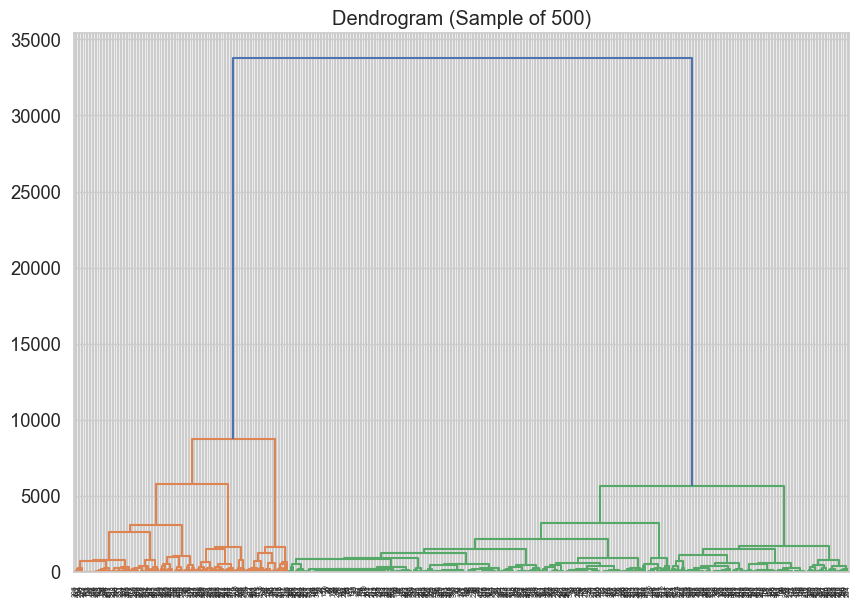

In [116]:
sample_X = X_reduced[:500]
linked = linkage(sample_X, 'ward')
plt.figure(figsize=(10, 7))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.title('Dendrogram (Sample of 500)')
plt.show()

In [117]:
from sklearn.decomposition import PCA
import plotly.express as px
import matplotlib.pyplot as plt

# Создаем PCA для визуализации (один раз для всех методов)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_reduced)

In [118]:
vis_df_agglo = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': df['agglo_cluster'].astype(str),
    'role': df['role']
})

fig_agglo = px.scatter(
    vis_df_agglo, x='PC1', y='PC2', color='cluster', symbol='role',
    title='Agglomerative Clustering (иерархическая кластеризация)',
    labels={'cluster': 'Кластер', 'role': 'Исходная роль'},
    width=1000, height=700
)
fig_agglo.show()

###DBSCAN

In [119]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
df['dbscan_cluster'] = dbscan.fit_predict(X_reduced)
n_clusters_db = len(set(df['dbscan_cluster'])) - (1 if -1 in df['dbscan_cluster'] else 0)
n_noise = list(df['dbscan_cluster']).count(-1)
print(f"DBSCAN Clusters: {n_clusters_db}, Noise points: {n_noise}")
db_sil = silhouette_score(X_reduced, df['dbscan_cluster']) if n_clusters_db > 1 else 'N/A'
print(f"DBSCAN Silhouette: {db_sil}")

DBSCAN Clusters: 16, Noise points: 12684
DBSCAN Silhouette: -0.7333089737469349


In [120]:
vis_df_dbscan = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': df['dbscan_cluster'].astype(str),
    'role': df['role']
})

fig_dbscan = px.scatter(
    vis_df_dbscan, x='PC1', y='PC2', color='cluster', symbol='role',
    title='DBSCAN (плотностная кластеризация)',
    labels={'cluster': 'Кластер', 'role': 'Исходная роль'},
    width=1000, height=700
)
fig_dbscan.show()

###GaussianMixture

In [121]:
gmm = GaussianMixture(n_components=4, random_state=42)
df['gmm_cluster'] = gmm.fit_predict(X_reduced)
gmm_sil = silhouette_score(X_reduced, df['gmm_cluster'])
print(f"GMM Silhouette Score: {gmm_sil:.4f}")


GMM Silhouette Score: -0.0734


In [122]:
vis_df_gmm = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'cluster': df['gmm_cluster'].astype(str),
    'role': df['role']
})

fig_gmm = px.scatter(
    vis_df_gmm, x='PC1', y='PC2', color='cluster', symbol='role',
    title='Gaussian Mixture Model (вероятностная модель)',
    labels={'cluster': 'Кластер', 'role': 'Исходная роль'},
    width=1000, height=700
)
fig_gmm.show()